In [198]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from hcipy import * 
from psfGenerator import PsfGenerator
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [199]:
wavelength = 764E-9
bw = 126E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq,snr_threshold=2,speckle_window=70)

PsfGen = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=bw_normalized, focal_sampling=6, focal_extent=80,grating_angle=grating_angle, fx=grating_freq, fy = grating_freq, mask=True)

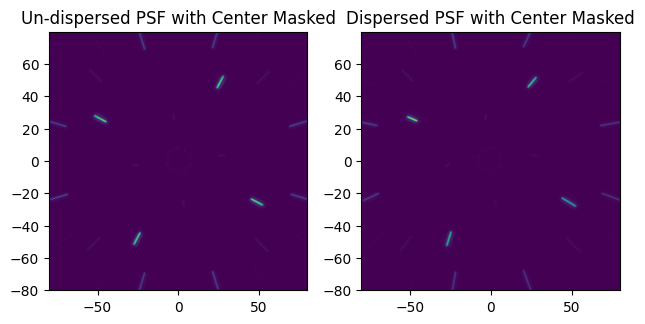

In [200]:
mag = 0.1
angle = 45

psf0 = PsfGen.polar_psf()
psf = PsfGen.polar_psf(magnitude=mag, orientation = angle)
plt.subplot(1,2,2)
imshow_field(psf)
plt.title('Dispersed PSF with Center Masked')
plt.subplot(1,2,1)
imshow_field(psf0)
plt.title('Un-dispersed PSF with Center Masked')
plt.tight_layout()
plt.show()

In [201]:
#let's draw some lines.
img = psf0

angle1,center1 = ADC.slice_speckle_angle(img,0,True)
angle2,center2 = ADC.slice_speckle_angle(img,1,True)
angle3,center3 = ADC.slice_speckle_angle(img,2,True)
angle4,center4 = ADC.slice_speckle_angle(img,3,True)

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:23: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


intersection point: (-0.008246603372670323,-0.04056754974737768)
center of intensity: (0.06417135369412842,-0.07061183348418366)


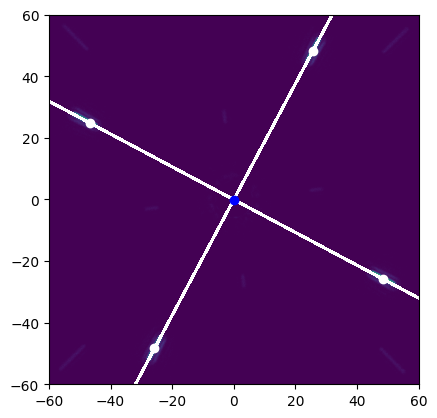

In [202]:
plt.figure()
imshow_field(img)
plt.plot(center1[0],center1[1],'o',color='white')
plt.plot(center2[0],center2[1],'o',color='white')
plt.plot(center3[0],center3[1],'o',color='white')
plt.plot(center4[0],center4[1],'o',color='white')

xs1 = np.array([center1[0],center3[0]])
ys1 = np.array([center1[1],center3[1]])

xs2 = np.array([center2[0],center4[0]])
ys2 = np.array([center2[1],center4[1]])

a = np.array(img.grid.x)
slope1,intercept1 = np.polyfit(xs1,ys1,deg=1) 
slope2,intercept2 = np.polyfit(xs2,ys2,deg=1) 

#intersection between the two lines
x_int = (intercept2 - intercept1) / (slope1 - slope2)
y_int = slope1 * x_int + intercept1
print(f'intersection point: ({x_int},{y_int})')

#compared to: center of intensity
center_of_intensity = np.array([sum(img*img.grid.x)/sum(img),sum(img*img.grid.y)/sum(img)])
print(f'center of intensity: ({center_of_intensity[0]},{center_of_intensity[1]})')

plt.plot(a, slope1 * a + intercept1,'w--')
plt.plot(a, slope2 * a + intercept2,'w--')
plt.plot(x_int,y_int,'bo')
plt.xlim((-60,60))
plt.ylim((-60,60))
plt.show()

In [140]:
#which is a better metric? let's run a bunch of trials to find out. vary mag and orientation to see if they affect it.
# trials = 100
# mags = np.random.rand(trials) * 0.1
# orientations = np.random.rand(trials) * 90

# intersections_offsets = np.zeros(trials)
# centers_offsets = np.zeros(trials)

# #magnitudes
# for i,mag in enumerate(mags):
#     img = PsfGen.polar_psf(magnitude=mag, orientation = 90)
#     angle1,center1 = ADC.slice_speckle_angle(img,0,True)
#     angle2,center2 = ADC.slice_speckle_angle(img,1,True)
#     angle3,center3 = ADC.slice_speckle_angle(img,2,True)
#     angle4,center4 = ADC.slice_speckle_angle(img,3,True)

#     xs1 = np.array([center1[0],center3[0]])
#     ys1 = np.array([center1[1],center3[1]])

#     xs2 = np.array([center2[0],center4[0]])
#     ys2 = np.array([center2[1],center4[1]])

#     a = np.array(img.grid.x)
#     slope1,intercept1 = np.polyfit(xs1,ys1,deg=1) 
#     slope2,intercept2 = np.polyfit(xs2,ys2,deg=1) 

#     x_int = (intercept2 - intercept1) / (slope1 - slope2)
#     y_int = slope1 * x_int + intercept1
#     #print(f'intersection point: ({x_int},{y_int})')

#     center_of_intensity = np.array([sum(img*img.grid.x)/sum(img),sum(img*img.grid.y)/sum(img)])
#     #print(f'center of intensity: ({center_of_intensity[0]},{center_of_intensity[1]})')

#     intersections_offsets[i] = np.sqrt(x_int**2+y_int**2)
#     centers_offsets[i] = np.sqrt(center_of_intensity[0]**2 + center_of_intensity[1]**2)


In [141]:
# plt.figure()
# plt.scatter(mags,intersections_offsets,label='intersection method')
# plt.scatter(mags,centers_offsets,label='center of intensity method')
# plt.legend()
# plt.xlabel('dipsersion magnitude')
# plt.ylabel('centroiding error')

# print(f'variance of intersection method {np.var(intersections_offsets)}, variance of intensity method {np.var(centers_offsets)}')

In [142]:
#which is a better metric? let's run a bunch of trials to find out. vary mag and orientation to see if they affect it.
# trials = 100
# mags = np.random.rand(trials) * 0.1
# orientations = np.random.rand(trials) * 90

# intersections_offsets1 = np.zeros(trials)
# centers_offsets1 = np.zeros(trials)

# #magnitudes
# for i,angle in enumerate(orientations):
#     img = PsfGen.polar_psf(magnitude=0.05, orientation = angle)
#     angle1,center1 = ADC.slice_speckle_angle(img,0,True)
#     angle2,center2 = ADC.slice_speckle_angle(img,1,True)
#     angle3,center3 = ADC.slice_speckle_angle(img,2,True)
#     angle4,center4 = ADC.slice_speckle_angle(img,3,True)

#     xs1 = np.array([center1[0],center3[0]])
#     ys1 = np.array([center1[1],center3[1]])

#     xs2 = np.array([center2[0],center4[0]])
#     ys2 = np.array([center2[1],center4[1]])

#     a = np.array(img.grid.x)
#     slope1,intercept1 = np.polyfit(xs1,ys1,deg=1) 
#     slope2,intercept2 = np.polyfit(xs2,ys2,deg=1) 

#     x_int = (intercept2 - intercept1) / (slope1 - slope2)
#     y_int = slope1 * x_int + intercept1
#     #print(f'intersection point: ({x_int},{y_int})')

#     center_of_intensity = np.array([sum(img*img.grid.x)/sum(img),sum(img*img.grid.y)/sum(img)])
#     #print(f'center of intensity: ({center_of_intensity[0]},{center_of_intensity[1]})')

#     intersections_offsets1[i] = np.sqrt(x_int**2+y_int**2)
#     centers_offsets1[i] = np.sqrt(center_of_intensity[0]**2 + center_of_intensity[1]**2)


In [143]:
# plt.figure()
# plt.scatter(orientations,intersections_offsets1,label='intersection method')
# plt.scatter(orientations,centers_offsets1,label='center of intensity method')
# plt.legend()
# plt.xlabel('dipsersion orientation (°)')
# plt.ylabel('centroiding error')

# print(f'variance of intersection method {np.var(intersections_offsets1)}, variance of intensity method {np.var(centers_offsets1)}')

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/hcipy/optics/aberration.py:38: RuntimeWarning: divide by zero encountered in power
  res = Field(grid.as_('polar').r**exponent, grid)


[ 55.91218886 -23.00331089  72.4710453  -31.00879957]
1.4776708616956662
3.166015018314751
intersection point 1&3: (-13.534359141474193,-9.695402738880482)
-0.4245430155328105
-0.6010696677939427
intersection point 2&4: (10.776099692331407,-9.78889668798675)


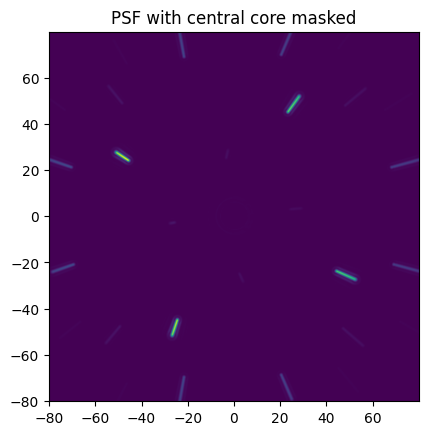

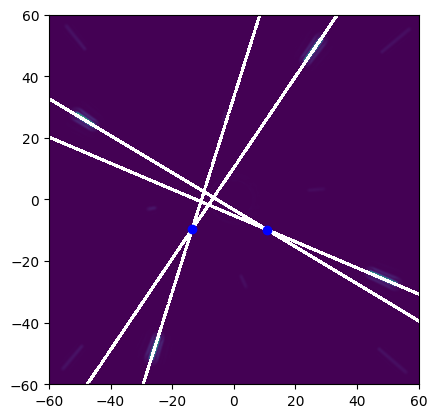

In [204]:
#ok well that about settles it. we'll just use the centroid of the whole image - which, even in the lab images, should be the center of the window,
# given that that's how i find where to window in the first place. maybe i'll just assume zero is zero after all. 

#generate image
disp = 0.08
orientation = 0
psf = PsfGen.polar_psf(magnitude=disp,orientation=orientation,num_photons=1E9,ptv=0)
imshow_field(psf)
plt.title('PSF with central core masked')

a = ADC.all_speckle_angles(psf)
print(a)

#use a slope and a point on each of the speckles to do point-slope form and convert to y = mx + b form. 
angle1, point1 = ADC.slice_speckle_angle(psf,0,positions=True)
slope1 = np.tan(np.radians(angle1))
intercept1 = -slope1 * point1[0] + point1[1]
print(slope1)

angle3, point3 = ADC.slice_speckle_angle(psf,2,positions=True)
slope3 = np.tan(np.radians(angle3))
intercept3 = -slope3 * point3[0] + point3[1]
print(slope3)

#now that we know the equations for each line, we can find the intersection point using the formula from before
x_int13 = (intercept3 - intercept1) / (slope1 - slope3)
y_int13 = slope1 * x_int13 + intercept1
print(f'intersection point 1&3: ({x_int13},{y_int13})')

plt.figure()
imshow_field(psf)
a = np.array(psf.grid.x)
plt.plot(a, slope1 * a + intercept1,'w--')
plt.plot(a, slope3 * a + intercept3,'w--')
plt.plot(x_int13,y_int13,'bo')
plt.xlim((-60,60))
plt.ylim((-60,60))

#plt.show()

angle2, point2 = ADC.slice_speckle_angle(psf,1,positions=True)
slope2 = np.tan(np.radians(angle2))
intercept2 = -slope2 * point2[0] + point2[1]
print(slope2)

angle4, point4 = ADC.slice_speckle_angle(psf,3,positions=True)
slope4 = np.tan(np.radians(angle4))
intercept4 = -slope4 * point4[0] + point4[1]
print(slope4)

#now that we know the equations for each line, we can find the intersection point using the formula from before
x_int24 = (intercept4 - intercept2) / (slope2 - slope4)
y_int24 = slope2 * x_int24 + intercept2
print(f'intersection point 2&4: ({x_int24},{y_int24})')

# plt.figure()
# imshow_field(psf)
# a = np.array(psf.grid.x)
plt.plot(a, slope2 * a + intercept2,'w--')
plt.plot(a, slope4 * a + intercept4,'w--')
plt.plot(x_int24,y_int24,'bo')
plt.xlim((-60,60))
plt.ylim((-60,60))
plt.show()


In [205]:
#now we need to find the point in the picture that is closest to all of the four lines at once.

#a,b,c coefficients
line1 = np.array([slope1, -1, point1[1]-slope1*point1[0]])
line2 = np.array([slope2, -1, point2[1]-slope2*point2[0]])
line3 = np.array([slope3, -1, point3[1]-slope3*point3[0]])
line4 = np.array([slope4, -1, point4[1]-slope4*point4[0]])

lines = np.stack((line1,line2,line3,line4))

A = lines[:,0]
B = lines[:,1]
C = lines[:,2]
norm = np.sqrt(A**2 + B**2)

A /= norm
B /= norm
C /= norm

M = np.stack((A.T,B.T),axis=1)
C = -C

(x, y), *_ = np.linalg.lstsq(M, C)
print(f'least-squares solution: ({x},{y})')
orientation_guess = np.atan(y/x)
print(f'Estimated dispersion direction {np.degrees(orientation_guess)}')

least-squares solution: (-8.760987202253734,-0.08516346905361095)
Estimated dispersion direction 0.5569410784538015


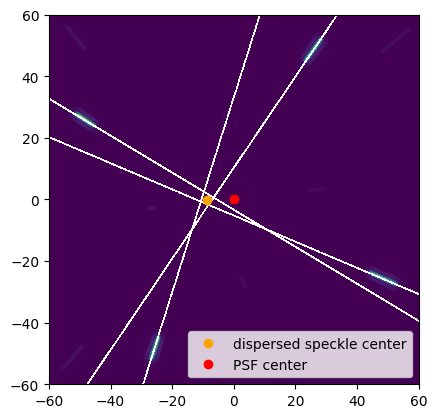

In [206]:
plt.figure()
imshow_field(psf)
a = np.array(psf.grid.x)
plt.plot(a, slope1 * a + intercept1,'w--',linewidth=0.5)
plt.plot(a, slope3 * a + intercept3,'w--',linewidth=0.5)
#plt.plot(x_int13,y_int13,'bo')

plt.plot(a, slope2 * a + intercept2,'w--',linewidth=0.5)
plt.plot(a, slope4 * a + intercept4,'w--',linewidth=0.5)
#plt.plot(x_int24,y_int24,'bo')

plt.plot(x,y,'o',color='orange',label='dispersed speckle center')
plt.plot(0,0,'o',color='red',label='PSF center')

plt.xlim((-60,60))
plt.ylim((-60,60))
plt.legend()
plt.show()

In [207]:
#ok now to distill it into one function
def est_mag_dir(psf):
    slopes = np.zeros(4)
    intercepts = np.zeros(4)
    points = []
    lines = np.zeros((4,3))

    for i in range(4):
        angle,point = ADC.slice_speckle_angle(psf,i,positions=True)
        slope = np.tan(np.radians(angle))
        slopes[i] = slope
        points.append(point)
        intercepts[i] = -slope * point[0] + point[1]

    for j in range(4):
        lines[j,0] = slopes[j]
        lines[j,1] = -1
        lines[j,2] = points[j][1] - slopes[j]*points[j][0]

    A = lines[:,0]
    B = lines[:,1]
    C = lines[:,2]
    norm = np.sqrt(A**2 + B**2)

    A /= norm
    B /= norm
    C /= norm

    M = np.stack((A.T,B.T),axis=1)
    C = -C

    (x, y), *_ = np.linalg.lstsq(M, C)
    print(f'least-squares solution: ({x},{y})')
    orientation_guess = np.atan(y/x)
    magnitude_guess = np.sqrt(x**2+y**2) / 100
    print(f'Estimated dispersion direction {np.degrees(orientation_guess)}°')
    print(f'Estimated dispersion magnitude {magnitude_guess}')


In [209]:
disp = 0.05
orientation = 0
psf = PsfGen.polar_psf(magnitude=disp,orientation=orientation,num_photons=1E9,ptv=0)

est_mag_dir(psf)

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/hcipy/optics/aberration.py:38: RuntimeWarning: divide by zero encountered in power
  res = Field(grid.as_('polar').r**exponent, grid)


least-squares solution: (-5.497892482895064,-0.06372616020859916)
Estimated dispersion direction 0.6640865626882227°
Estimated dispersion magnitude 0.05498261795965065
